# Analiza ważności 64 wskaźników finansowych — HGB

**Cel:** sprawdzić, które wskaźniki `Attr1`–`Attr64` najmocniej wpływają na jakość predykcji bankructwa. Wynikami będą ranking TOP 10, wykres oraz tabela CSV dla pracy inżynierskiej.

Ten notebook **nie trenuje ponownie modelu**. Wczytuje zapisany model `model_bankructwo_5year.joblib` oraz dane `5year.arff`, a następnie wykonuje analizę **ważności permutacyjnej** (*permutation importance*).

**Ważne:** jest to analiza interpretacyjna istniejącego modelu, a **nie selekcja cech**. Nie usuwaj wskaźników ani nie poprawiaj modelu na podstawie wyniku tej analizy na zbiorze testowym — do takich decyzji użyj danych treningowych i nowej walidacji.

## 1. Przygotowanie środowiska

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from scipy.io import arff
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
PLIK_DANE = Path("5year.arff")
PLIK_MODELU = Path("model_bankructwo_5year.joblib")

for sciezka in [PLIK_DANE, PLIK_MODELU]:
    if not sciezka.is_file():
        raise FileNotFoundError(
            f"Nie znaleziono {sciezka}. Umieść plik obok notebooka lub popraw ścieżkę."
        )
print("Pliki znalezione. Można rozpocząć analizę.")

Pliki znalezione. Można rozpocząć analizę.


## 2. Definicja transformatora i wczytanie modelu

W oryginalnym notebooku transformator `QuantileClipper` był zdefiniowany jako własna klasa. Jej obecność jest potrzebna podczas odczytu zapisanego obiektu `.joblib`. Jeżeli przy wczytywaniu pojawi się błąd dotyczący tej klasy, uruchom najpierw tę komórkę.

In [2]:
class QuantileClipper(BaseEstimator, TransformerMixin):
    """Ta sama definicja klasy co w notebooku trenującym."""

    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        a = np.asarray(X, dtype=float)
        self.lower_ = np.nanquantile(a, self.lower, axis=0)
        self.upper_ = np.nanquantile(a, self.upper, axis=0)
        return self

    def transform(self, X):
        a = np.asarray(X, dtype=float)
        return np.clip(a, self.lower_, self.upper_)

zapis = joblib.load(PLIK_MODELU)
model = zapis["pipeline"]
cechy = list(zapis["feature_names"])
prog = float(zapis["threshold"])

assert len(cechy) == 64, f"Oczekiwano 64 cech, znaleziono {len(cechy)}"
print("Wczytano model:", type(model.named_steps["model"]).__name__)
print("Liczba cech:", len(cechy))
print("Próg klasyfikacji:", round(prog, 5))

Wczytano model: HistGradientBoostingClassifier
Liczba cech: 64
Próg klasyfikacji: 0.08113


## 3. Odtworzenie zbioru testowego

Wykonujemy **dokładnie takie samo czyszczenie duplikatów i podział** jak w pierwszym notebooku: `test_size=0.20`, `stratify=y`, `random_state=42`. Bez tego ranking nie dotyczyłby tego samego zbioru testowego.

In [3]:
rekordy, meta = arff.loadarff(str(PLIK_DANE))
kolumny = [n for n in rekordy.dtype.names if n != "class"]
X = pd.DataFrame({n: rekordy[n].astype(float) for n in kolumny})
y = pd.Series([int(k.decode("ascii")) if isinstance(k, bytes) else int(k)
               for k in rekordy["class"]], name="class")

dane = X.copy()
dane["class"] = y
dane = dane.drop_duplicates().reset_index(drop=True)
y = dane.pop("class").astype(int)
X = dane

brakujace = set(cechy) - set(X.columns)
if brakujace:
    raise ValueError(f"W danych brakuje wskaźników: {sorted(brakujace)}")
X = X.loc[:, cechy]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Liczba obserwacji testowych:", len(X_test))
print("Liczba bankructw w teście:", int(y_test.sum()))
print("Liczba wskaźników:", X_test.shape[1])
assert len(X_test) == 1170 and int(y_test.sum()) == 82, (
    "Podział różni się od dotychczasowego! Sprawdź, czy używasz tego samego 5year.arff."
)

Liczba obserwacji testowych: 1170
Liczba bankructw w teście: 82
Liczba wskaźników: 64


## 4. Kontrola zgodności z wcześniejszym wynikiem

Dla Twojego zapisanego modelu oczekiwany wynik AP na teście wynosił około **0,8474**. Jeżeli wynik będzie inny, sprawdź, czy plik `.joblib` pochodzi z najnowszego treningu.

In [4]:
p_test = model.predict_proba(X_test)[:, 1]
ap_test = average_precision_score(y_test, p_test)
print(f"Average Precision na zbiorze testowym: {ap_test:.4f}")
if abs(ap_test - 0.8474) > 0.02:
    print("UWAGA: AP różni się od wcześniejszego wyniku 0,8474. Zweryfikuj wersję modelu.")

Average Precision na zbiorze testowym: 0.8474


## 5. Ważność permutacyjna wszystkich 64 wskaźników

Dla każdej cechy osobno kilkukrotnie **losowo przestawiamy jej wartości pomiędzy firmami**, pozostawiając inne wskaźniki bez zmian. Następnie mierzymy, o ile spadła metryka **Average Precision (AP)**.

**Interpretacja:** im większy średni spadek AP, tym bardziej model polega na danej cesze. Ważność bliska zeru oznacza niewielki wpływ w tym eksperymencie. Wartości ujemne mogą pojawić się przez zmienność pomiaru. Przy silnie skorelowanych wskaźnikach ranking może zaniżać znaczenie pojedynczych cech.

`n_repeats=5` to kompromis między stabilnością i czasem obliczeń. Możesz ustawić `3`, jeśli wykonywanie będzie zbyt wolne.

In [5]:
wynik_perm = permutation_importance(
    estimator=model,
    X=X_test,
    y=y_test,
    scoring="average_precision",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=1,
)

ranking = pd.DataFrame({
    "Wskaznik": cechy,
    "Spadek_AP_sredni": wynik_perm.importances_mean,
    "Spadek_AP_odch_std": wynik_perm.importances_std,
    "Braki_w_tescie_proc": X_test[cechy].isna().mean().mul(100).to_numpy(),
}).sort_values("Spadek_AP_sredni", ascending=False).reset_index(drop=True)
ranking.index += 1
ranking.index.name = "Pozycja"
print("TOP 10 wskaźników:")
print(ranking.head(10).round(4).to_string())

TOP 10 wskaźników:
        Wskaznik  Spadek_AP_sredni  Spadek_AP_odch_std  Braki_w_tescie_proc
Pozycja                                                                    
1         Attr27            0.3232              0.0178               6.2393
2         Attr21            0.2778              0.0221               2.0513
3         Attr34            0.1410              0.0069               0.4274
4         Attr58            0.0363              0.0036               0.0000
5         Attr46            0.0362              0.0048               0.5128
6         Attr24            0.0309              0.0078               2.3932
7         Attr35            0.0308              0.0066               0.0855
8         Attr56            0.0216              0.0022               0.0000
9         Attr39            0.0133              0.0078               0.0000
10         Attr5            0.0101              0.0055               0.1709


## 6. Wykres TOP 10 wskaźników

Długość słupka oznacza średni **spadek AP po przetasowaniu** wartości danego wskaźnika. To nie jest procent udziału wskaźnika w predykcji ani związek przyczynowo-skutkowy.

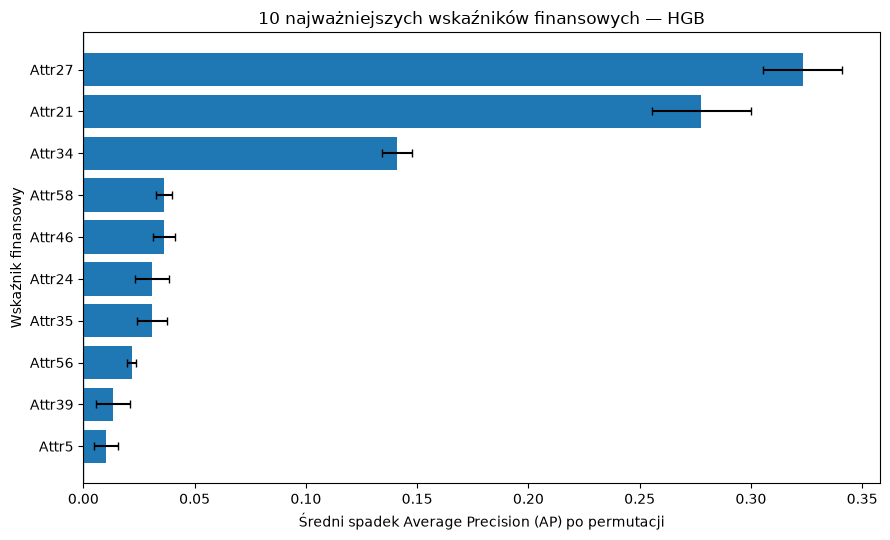

Zapisano: waznosc_wskaznikow_top10.png


In [6]:
top10 = ranking.head(10).sort_values("Spadek_AP_sredni", ascending=True)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top10["Wskaznik"], top10["Spadek_AP_sredni"],
        xerr=top10["Spadek_AP_odch_std"], capsize=3)
ax.axvline(0, linewidth=1)
ax.set_xlabel("Średni spadek Average Precision (AP) po permutacji")
ax.set_ylabel("Wskaźnik finansowy")
ax.set_title("10 najważniejszych wskaźników finansowych — HGB")
fig.tight_layout()
fig.savefig("waznosc_wskaznikow_top10.png", dpi=180, bbox_inches="tight")
plt.show()
print("Zapisano: waznosc_wskaznikow_top10.png")

## 7. Zapis wyników 

Zapisujemy cały ranking i skróconą tabelę. **Model wciąż wymaga 64 cech.** Ranking TOP 10 **nie oznacza**, że można przekazywać do aplikacji tylko 10 wskaźników.

In [7]:
ranking.to_csv("ranking_64_wskaznikow.csv", index=True, encoding="utf-8-sig")
ranking.head(10).to_csv("ranking_top10_wskaznikow.csv", index=True, encoding="utf-8-sig")
print("Zapisano: ranking_64_wskaznikow.csv")
print("Zapisano: ranking_top10_wskaznikow.csv")

Zapisano: ranking_64_wskaznikow.csv
Zapisano: ranking_top10_wskaznikow.csv


### TOP 10 najważniejszych wskaźników finansowych – znaczenie

| Pozycja | Wskaźnik | Znaczenie w języku polskim |
|---|---|---|
| 1 | **Attr27** | Zysk z działalności operacyjnej / koszty finansowe |
| 2 | **Attr21** | Przychody ze sprzedaży w bieżącym roku / przychody ze sprzedaży w poprzednim roku |
| 3 | **Attr34** | Koszty operacyjne / zobowiązania ogółem |
| 4 | **Attr58** | Koszty całkowite / przychody ze sprzedaży ogółem |
| 5 | **Attr46** | (Aktywa obrotowe − zapasy) / zobowiązania krótkoterminowe |
| 6 | **Attr24** | Zysk brutto z ostatnich 3 lat / aktywa ogółem |
| 7 | **Attr35** | Zysk ze sprzedaży / aktywa ogółem |
| 8 | **Attr56** | (Przychody ze sprzedaży − koszt sprzedanych produktów) / przychody ze sprzedaży |
| 9 | **Attr39** | Zysk ze sprzedaży / przychody ze sprzedaży |
| 10 | **Attr5** | Wskaźnik płynności uwzględniający środki pieniężne, należności, zobowiązania krótkoterminowe i koszty operacyjne, wyrażony w dniach |

## 8. do pracy inżynierskiej

> W celu interpretacji działania wybranego klasyfikatora HistGradientBoosting przeprowadzono analizę ważności permutacyjnej dla 64 wskaźników finansowych. Dla każdego wskaźnika pięciokrotnie losowo zmieniano przyporządkowanie jego wartości do przedsiębiorstw w zbiorze testowym, mierząc zmianę wartości Average Precision. Większy spadek AP wskazuje na większą zależność predykcji modelu od danego wskaźnika. Wyniki przedstawiono w formie rankingu i wykresu dziesięciu najwyżej ocenionych cech. Ze względu na potencjalne współzależności między wskaźnikami ranking ma charakter interpretacyjny i nie jest dowodem związku przyczynowego.

Po uruchomieniu notebooka uzupełnij ten opis o **rzeczywiste nazwy wskaźników TOP 10 i ich wartości**. Definicje `Attr1`–`Attr64` sprawdzaj w dokumentacji zbioru danych, zamiast zgadywać je z numerów.

### Ważne ograniczenia

- Analizę przeprowadzono na już ocenionym zbiorze testowym. **Nie używaj jej wyniku do zmiany modelu, progu lub wyboru cech**, jeśli chcesz zachować niezależność oceny testowej.
- Przy wskaźnikach skorelowanych pojedyncza ważność permutacyjna może być mała mimo istotności grupy cech.
- Ranking nie dowodzi, że model zachowa wynik po ograniczeniu liczby wskaźników. Taki krok wymaga ponownego treningu i walidacji na danych treningowych.
- Ważność wskaźników nie jest równoważna kierunkowi wpływu (dodatni/ujemny) ani wyjaśnieniu pojedynczej decyzji modelu.